# Titanic Passenger Survival Prediction using Logistic Regression

**Goal:** Predict whether a passenger survived (1) or not (0) from details like class, sex, age and fare.

**Model:** Logistic Regression  |  **Dataset:** Titanic (891 passengers)

In [1]:
# STEP 1 : Import Required Libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
for folder in ["graphs", "confusion_matrix", "metrics", "predictions"]:
    os.makedirs(f"../outputs/{folder}", exist_ok=True)

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
# STEP 2 : Load Dataset
df = pd.read_csv("../dataset/titanic.csv")
print("Dataset loaded successfully.")

Dataset loaded successfully.


In [3]:
# STEP 3 : First Look at the Data
display(df.head())

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
# STEP 4 : Shape of the Dataset
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

Rows    : 891
Columns : 15


In [5]:
# STEP 5 : Dataset Information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [6]:
# STEP 6 : Missing Values
missing = df.isna().sum()
print(missing[missing > 0])

age            177
embarked         2
deck           688
embark_town      2
dtype: int64


survived
0    549
1    342
Name: count, dtype: int64

survived
0    61.62
1    38.38
Name: proportion, dtype: float64


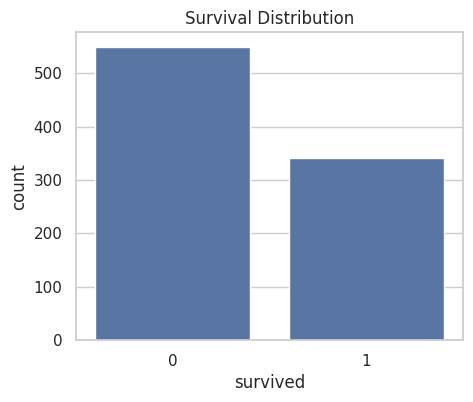

In [7]:
# STEP 7 : Target Variable Distribution
# survived = 1 -> passenger survived, survived = 0 -> did not survive
print(df["survived"].value_counts())
print()
print((df["survived"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(5,4))
sns.countplot(x="survived", data=df)
plt.title("Survival Distribution")
plt.show()

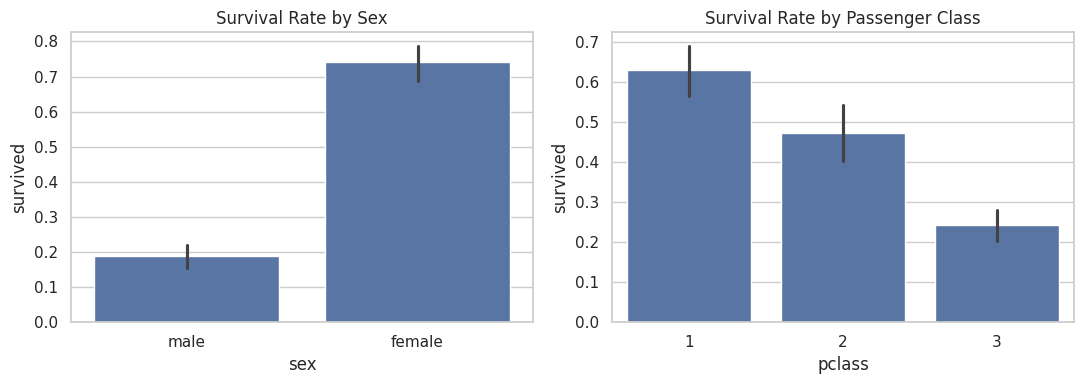

In [8]:
# STEP 8 : Exploratory Analysis
fig, ax = plt.subplots(1, 2, figsize=(11,4))
sns.barplot(x="sex", y="survived", data=df, ax=ax[0])
ax[0].set_title("Survival Rate by Sex")
sns.barplot(x="pclass", y="survived", data=df, ax=ax[1])
ax[1].set_title("Survival Rate by Passenger Class")
plt.tight_layout()
plt.show()

In [9]:
# STEP 9 : Remove Unnecessary Columns
# alive        -> same information as the target (data leakage!)
# class        -> duplicate of pclass
# embark_town  -> duplicate of embarked
# who, adult_male, alone -> already contained in sex, age, sibsp, parch
# deck         -> about 77% values are missing
df = df.drop(columns=["alive", "class", "embark_town", "who",
                      "adult_male", "alone", "deck"])

print("Remaining columns:", list(df.columns))
print("Shape:", df.shape)

Remaining columns: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
Shape: (891, 8)


In [10]:
# STEP 10 : Encode Categorical Features
# Convert text values into numbers for Logistic Regression
encoded_df = df.copy()

# Binary encoding for sex
encoded_df["sex"] = encoded_df["sex"].map({"male": 1, "female": 0})

# One-hot encoding for pclass and embarked
encoded_df = pd.get_dummies(
    encoded_df,
    columns=["pclass", "embarked"],
    drop_first=True
)

# Convert True/False columns into 1/0
bool_cols = encoded_df.select_dtypes(include="bool").columns
encoded_df[bool_cols] = encoded_df[bool_cols].astype(int)

print("Categorical columns encoded successfully.")
print("New Dataset Shape:", encoded_df.shape)
display(encoded_df.head())

Categorical columns encoded successfully.
New Dataset Shape: (891, 10)


,survived,sex,age,sibsp,parch,fare,pclass_2,pclass_3,embarked_Q,embarked_S
0,0,1,22.0,1,0,7.2500,0,1,0,1
1,1,0,38.0,1,0,71.2833,0,0,0,0
2,1,0,26.0,0,0,7.9250,0,1,0,1
3,1,0,35.0,1,0,53.1000,0,0,0,1
4,0,1,35.0,0,0,8.0500,0,1,0,1


In [11]:
# STEP 11 : Split Features and Target Variable
from sklearn.model_selection import train_test_split

y = encoded_df["survived"]
X = encoded_df.drop(columns=["survived"])

print("Features Shape :", X.shape)
print("Target Shape   :", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,     # 20% for testing
    random_state=42,    # same split every time
    stratify=y          # keep class ratio same in train and test
)

print("\nTraining Data :", X_train.shape)
print("Testing Data  :", X_test.shape)

Features Shape : (891, 9)
Target Shape   : (891,)

Training Data : (712, 9)
Testing Data  : (179, 9)


In [12]:
# STEP 12 : Handle Missing Values (AFTER the split, using training data only)
print("Missing values before filling:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

# Age is numeric -> median of the TRAINING data
age_median = X_train["age"].median()
X_train["age"] = X_train["age"].fillna(age_median)
X_test["age"]  = X_test["age"].fillna(age_median)

# Embarked was one-hot encoded, so its 2 missing rows became
# "not Q and not S" (treated as the dropped category C). No NaN remains.

print("\nMissing values left in training data:", X_train.isna().sum().sum())
print("Missing values left in testing data :", X_test.isna().sum().sum())

Missing values before filling:


age    137
dtype: int64

Missing values left in training data: 0
Missing values left in testing data : 0


In [13]:
# STEP 13 : Feature Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn from training data only
X_test_scaled  = scaler.transform(X_test)        # apply the SAME scaler

print("Feature scaling completed successfully!")
print("Scaled Training Shape :", X_train_scaled.shape)
print("Scaled Testing Shape  :", X_test_scaled.shape)

Feature scaling completed successfully!
Scaled Training Shape : (712, 9)
Scaled Testing Shape  : (179, 9)


In [14]:
# STEP 14 : Train Logistic Regression Model
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")
print("Number of features used:", X_train_scaled.shape[1])

Logistic Regression model trained successfully!
Number of features used: 9


In [15]:
# STEP 15 : Make Predictions on Test Data
y_pred = logistic_model.predict(X_test_scaled)                 # labels (0 or 1)
y_prob = logistic_model.predict_proba(X_test_scaled)[:, 1]     # probability of survival

print("First 10 Predicted Values:", y_pred[:10])
print("First 10 Probabilities   :", y_prob[:10].round(3))

First 10 Predicted Values: [0 0 0 0 1 0 1 0 0 0]
First 10 Probabilities   : [0.065 0.046 0.155 0.034 0.682 0.437 0.772 0.306 0.344 0.174]


In [16]:
# STEP 16 : Evaluate the Model
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)
print("=" * 50)
print("LOGISTIC REGRESSION MODEL PERFORMANCE")
print("=" * 50)
print(f"Model Accuracy : {accuracy:.4f}  ({accuracy*100:.2f}%)")
print()
print(classification_report(y_test, y_pred, target_names=["Did not survive", "Survived"]))

LOGISTIC REGRESSION MODEL PERFORMANCE
Model Accuracy : 0.8045  (80.45%)

                 precision    recall  f1-score   support

Did not survive       0.81      0.89      0.85       110
       Survived       0.79      0.67      0.72        69

       accuracy                           0.80       179
      macro avg       0.80      0.78      0.79       179
   weighted avg       0.80      0.80      0.80       179



True Positive  (TP) : 46
False Negative (FN) : 23
False Positive (FP) : 12
True Negative  (TN) : 98


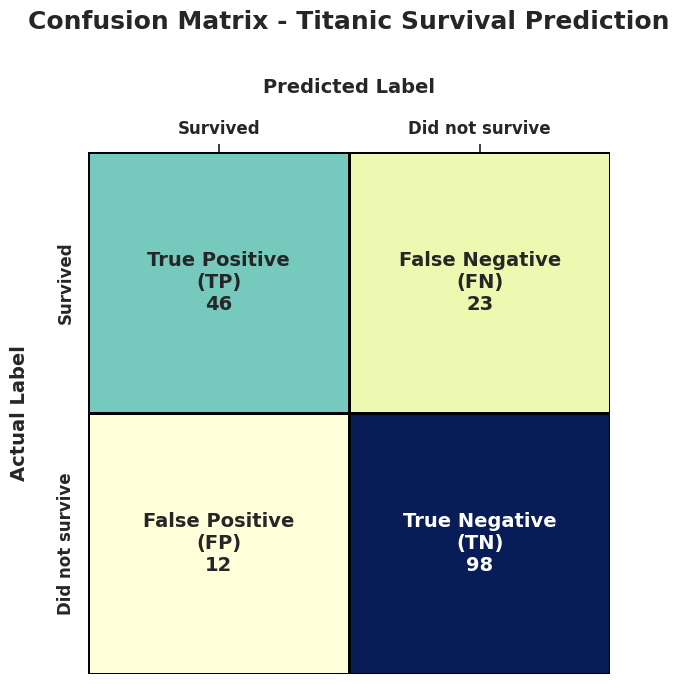

In [17]:
# STEP 17 : Confusion Matrix (positive class = Survived is shown first)
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[1, 0])
TP, FN, FP, TN = cm.ravel()

print(f"True Positive  (TP) : {TP}")
print(f"False Negative (FN) : {FN}")
print(f"False Positive (FP) : {FP}")
print(f"True Negative  (TN) : {TN}")

box_labels = [[f"True Positive\n(TP)\n{TP}", f"False Negative\n(FN)\n{FN}"],
              [f"False Positive\n(FP)\n{FP}", f"True Negative\n(TN)\n{TN}"]]

plt.figure(figsize=(8,7))
ax = sns.heatmap(cm, annot=box_labels, fmt="", cmap="YlGnBu", linewidths=2,
                 linecolor="black", cbar=False, square=True,
                 annot_kws={"fontsize":14, "fontweight":"bold"})
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
ax.set_xlabel("Predicted Label", fontsize=14, fontweight="bold", labelpad=20)
ax.set_ylabel("Actual Label", fontsize=14, fontweight="bold", labelpad=20)
ax.set_xticklabels(["Survived", "Did not survive"], fontsize=12, fontweight="bold")
ax.set_yticklabels(["Survived", "Did not survive"], fontsize=12, fontweight="bold", rotation=90)
plt.title("Confusion Matrix - Titanic Survival Prediction", fontsize=18, fontweight="bold", pad=35)
plt.tight_layout()
plt.savefig("../outputs/confusion_matrix/confusion_matrix_final.png", dpi=300, bbox_inches="tight")
plt.show()

AUC Score : 0.8422


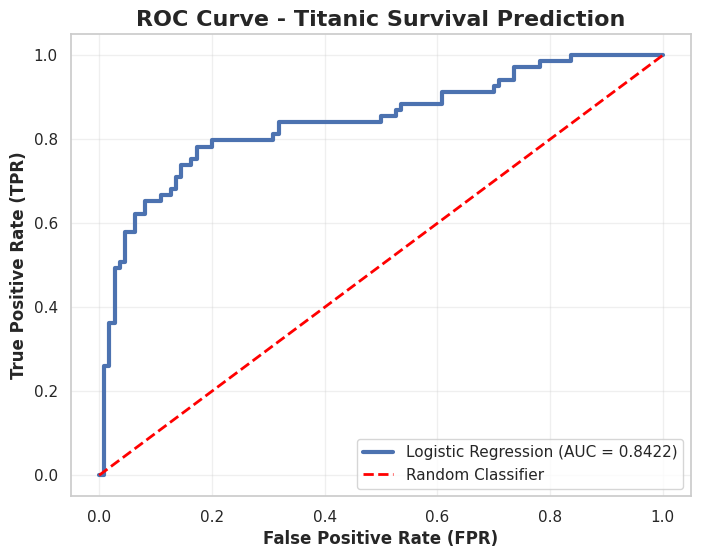

In [18]:
# STEP 18 : ROC Curve and AUC Score
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)
print(f"AUC Score : {auc_score:.4f}")

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, linewidth=3, label=f"Logistic Regression (AUC = {auc_score:.4f})")
plt.plot([0,1], [0,1], linestyle="--", linewidth=2, color="red", label="Random Classifier")
plt.title("ROC Curve - Titanic Survival Prediction", fontsize=16, fontweight="bold")
plt.xlabel("False Positive Rate (FPR)", fontsize=12, fontweight="bold")
plt.ylabel("True Positive Rate (TPR)", fontsize=12, fontweight="bold")
plt.grid(True, alpha=0.3)
plt.legend(loc="lower right")
plt.savefig("../outputs/graphs/roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

In [19]:
# STEP 19 : Precision, Recall and F1 Score
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred)
f1        = f1_score(y_test, y_pred)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "Value": [round(accuracy,4), round(precision,4), round(recall,4),
              round(f1,4), round(auc_score,4)]
})
display(metrics_df)
metrics_df.to_csv("../outputs/metrics/model_metrics.csv", index=False)

,Metric,Value
0,Accuracy,0.8045
1,Precision,0.7931
2,Recall,0.6667
3,F1 Score,0.7244
4,ROC-AUC,0.8422


,Feature,Coefficient,Importance
0,sex,-1.263371,1.263371
6,pclass_3,-1.069647,1.069647
1,age,-0.497303,0.497303
5,pclass_2,-0.373072,0.373072
2,sibsp,-0.260407,0.260407
8,embarked_S,-0.196180,0.196180
4,fare,0.121415,0.121415
7,embarked_Q,0.077811,0.077811
3,parch,-0.069776,0.069776


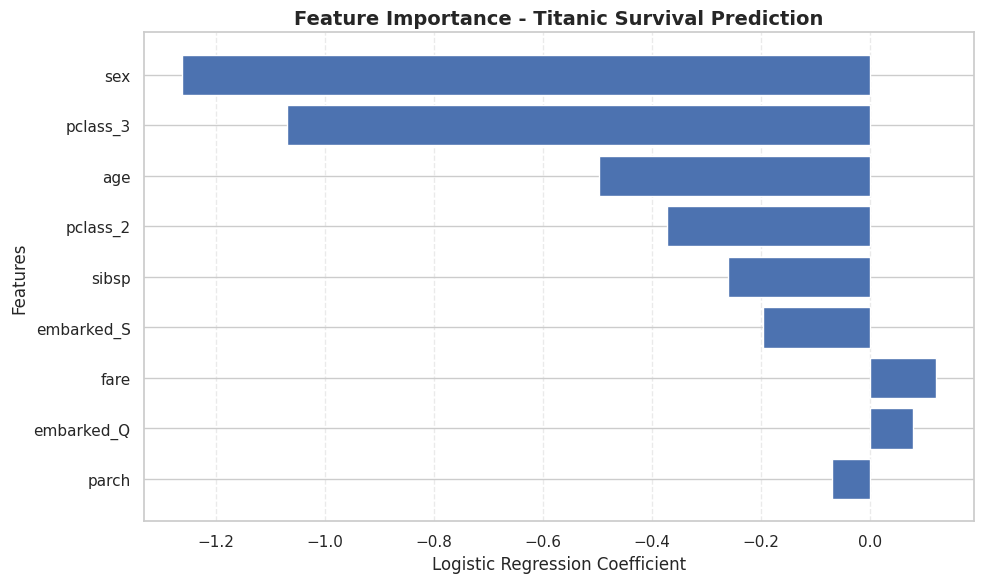

In [20]:
# STEP 20 : Feature Importance (Logistic Regression coefficients)
importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_model.coef_[0]
})
importance["Importance"] = importance["Coefficient"].abs()
importance = importance.sort_values(by="Importance", ascending=False)
display(importance)

plt.figure(figsize=(10,6))
plt.barh(importance["Feature"][::-1], importance["Coefficient"][::-1])
plt.title("Feature Importance - Titanic Survival Prediction", fontsize=14, fontweight="bold")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Features")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("../outputs/graphs/feature_importance.png", dpi=300)
plt.show()

In [21]:
# STEP 21 : Predict Survival for a New Passenger
new_passenger = pd.DataFrame(0, index=[0], columns=X.columns)
new_passenger["sex"]      = 0      # female
new_passenger["age"]      = 28
new_passenger["sibsp"]    = 0
new_passenger["parch"]    = 0
new_passenger["fare"]     = 80
new_passenger["pclass_2"] = 0
new_passenger["pclass_3"] = 0      # both 0 -> 1st class

# Scale using the SAME scaler used during training
new_scaled  = scaler.transform(new_passenger)
prediction  = logistic_model.predict(new_scaled)[0]
probability = logistic_model.predict_proba(new_scaled)[0][1]

display(new_passenger)
print(f"Probability of Survival : {probability:.2%}")
print("Prediction :", "Passenger is likely to SURVIVE." if prediction == 1
      else "Passenger is likely NOT to survive.")

,sex,age,sibsp,parch,fare,pclass_2,pclass_3,embarked_Q,embarked_S
0,0,28,0,0,80,0,0,0,0


Probability of Survival : 95.47%
Prediction : Passenger is likely to SURVIVE.


In [22]:
# STEP 22 : Save Test Predictions
prediction_results = pd.DataFrame({
    "Actual_Survived": y_test.values,
    "Predicted_Survived": y_pred,
    "Probability_of_Survival": y_prob
})
display(prediction_results.head(10))
prediction_results.to_csv("../outputs/predictions/titanic_predictions.csv", index=False)

,Actual_Survived,Predicted_Survived,Probability_of_Survival
0,0,0,0.065295
1,0,0,0.045748
2,1,0,0.154840
3,0,0,0.034349
4,1,1,0.681540
5,1,0,0.437441
6,1,1,0.771682
7,0,0,0.306499
8,0,0,0.343909
9,0,0,0.173905


## Investigation: Does the choice of metric change the conclusion?

We keep the **same model and same test set** and only change the decision threshold (0.3, 0.5, 0.7).

In [23]:
# STEP 23 : Threshold Comparison
thresholds_list = [0.3, 0.5, 0.7]
results = []

for t in thresholds_list:
    y_pred_t = (y_prob >= t).astype(int)
    results.append({
        "Threshold": t,
        "Accuracy":  round(accuracy_score(y_test, y_pred_t), 4),
        "Precision": round(precision_score(y_test, y_pred_t), 4),
        "Recall":    round(recall_score(y_test, y_pred_t), 4),
        "F1-Score":  round(f1_score(y_test, y_pred_t), 4)
    })

threshold_df = pd.DataFrame(results)
display(threshold_df)
threshold_df.to_csv("../outputs/metrics/threshold_comparison.csv", index=False)

,Threshold,Accuracy,Precision,Recall,F1-Score
0,0.3,0.7709,0.6707,0.7971,0.7285
1,0.5,0.8045,0.7931,0.6667,0.7244
2,0.7,0.7877,0.8974,0.5072,0.6481


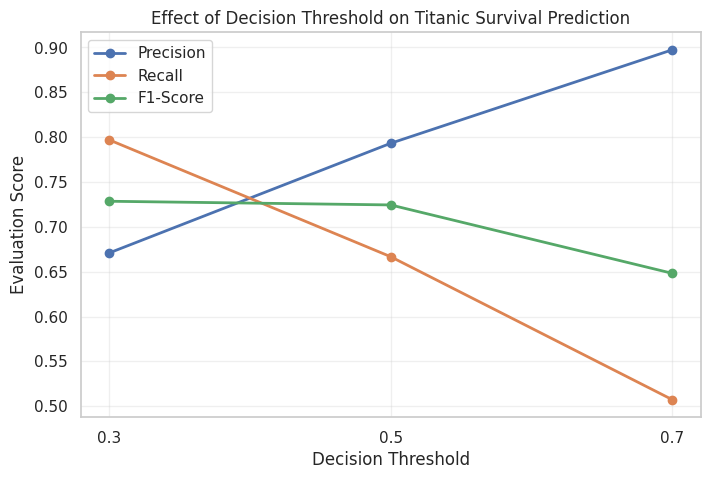

In [24]:
# STEP 24 : Threshold vs Evaluation Metrics Graph
plt.figure(figsize=(8,5))
for col in ["Precision", "Recall", "F1-Score"]:
    plt.plot(threshold_df["Threshold"], threshold_df[col], marker="o", linewidth=2, label=col)
plt.title("Effect of Decision Threshold on Titanic Survival Prediction")
plt.xlabel("Decision Threshold")
plt.ylabel("Evaluation Score")
plt.xticks([0.3, 0.5, 0.7])
plt.grid(True, alpha=0.3)
plt.legend()
plt.savefig("../outputs/graphs/threshold_comparison.png", dpi=300, bbox_inches="tight")
plt.show()